#Preparação do ambiente

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

CAMINHO_BASE = Path("/content/drive/MyDrive/ifes_projeto")
df_pandas = pd.read_csv(CAMINHO_BASE /"ifes_2010_2024.csv")

In [28]:
#Convertendo as três colunas que vieram como float para int
cols_int = ["num_vagas_estudantes", "num_vagas_docente", "num_vagas_tae"]
df_pandas[cols_int]= df_pandas[cols_int].astype(int)

In [29]:
#Visualização parcial dos dados da base
df_pandas.info()
display(df_pandas.head())
display(df_pandas.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   ano                                  15 non-null     int64  
 1   num_vagas_estudantes                 15 non-null     int64  
 2   num_vagas_docente                    15 non-null     int64  
 3   num_vagas_tae                        15 non-null     int64  
 4   investimento_total_ifes              15 non-null     float64
 5   investimento_assistencia_estudantil  15 non-null     float64
dtypes: float64(2), int64(4)
memory usage: 852.0 bytes


,ano,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,investimento_total_ifes,investimento_assistencia_estudantil
0,2010,282691,83443,100683,2.191072e+10,209886690.0
1,2011,300858,90388,109994,2.439646e+10,296538547.0
2,2012,322588,95615,115751,2.615179e+10,386078475.0
3,2013,399375,101376,115615,3.084262e+10,515723907.0
4,2014,471234,106631,129894,3.472919e+10,609525689.0


,count,mean,std,min,25%,50%,75%,max
ano,15.0,2.017000e+03,4.472136e+00,2.010000e+03,2.013500e+03,2.017000e+03,2.020500e+03,2.024000e+03
num_vagas_estudantes,15.0,4.545166e+05,9.314299e+04,2.826910e+05,4.263905e+05,4.712340e+05,4.918770e+05,5.931080e+05
num_vagas_docente,15.0,1.139424e+05,1.511018e+04,8.344300e+04,1.040035e+05,1.195440e+05,1.263590e+05,1.301310e+05
num_vagas_tae,15.0,1.276527e+05,1.266668e+04,1.006830e+05,1.211110e+05,1.298940e+05,1.328750e+05,1.466200e+05
investimento_total_ifes,15.0,4.152261e+10,1.174641e+10,2.191072e+10,3.278591e+10,4.483874e+10,4.953406e+10,5.906843e+10
investimento_assistencia_estudantil,15.0,6.948608e+08,2.474057e+08,2.098867e+08,5.626248e+08,8.111484e+08,8.301053e+08,1.074812e+09


#Inicio

##Etapa 2.1

In [30]:
#Ordens de grandeza de cada coluna da base de dados
ordem = (df_pandas.drop(columns="ano").median()
           .apply(lambda x: 10 ** np.floor(np.log10(x))))
print(ordem)

num_vagas_estudantes                   1.000000e+05
num_vagas_docente                      1.000000e+05
num_vagas_tae                          1.000000e+05
investimento_total_ifes                1.000000e+10
investimento_assistencia_estudantil    1.000000e+08
dtype: float64


Observa-se acima a ordem de grandeza da mediana de cada uma das variáveis presentes na base de dados original. Pela análise da mediana dos dados, pode-se observar que se distribuem sob três ordens de grandeza: 10^10, 10^8 e 10^5, com uma "amplitude" de até 100.000x (ou 10^5) entre os números de vagas (ordem de 10^5) e o investimento total dos ifes (ordem de 10^10). Vale observar que uma possível comparação entre num_vagas e investimento deve levar em conta, além da disparidade nas ordens de grandeza, as diferentes unidades de medida (vagas e reais, respectivamente).

##Etapa 2.2

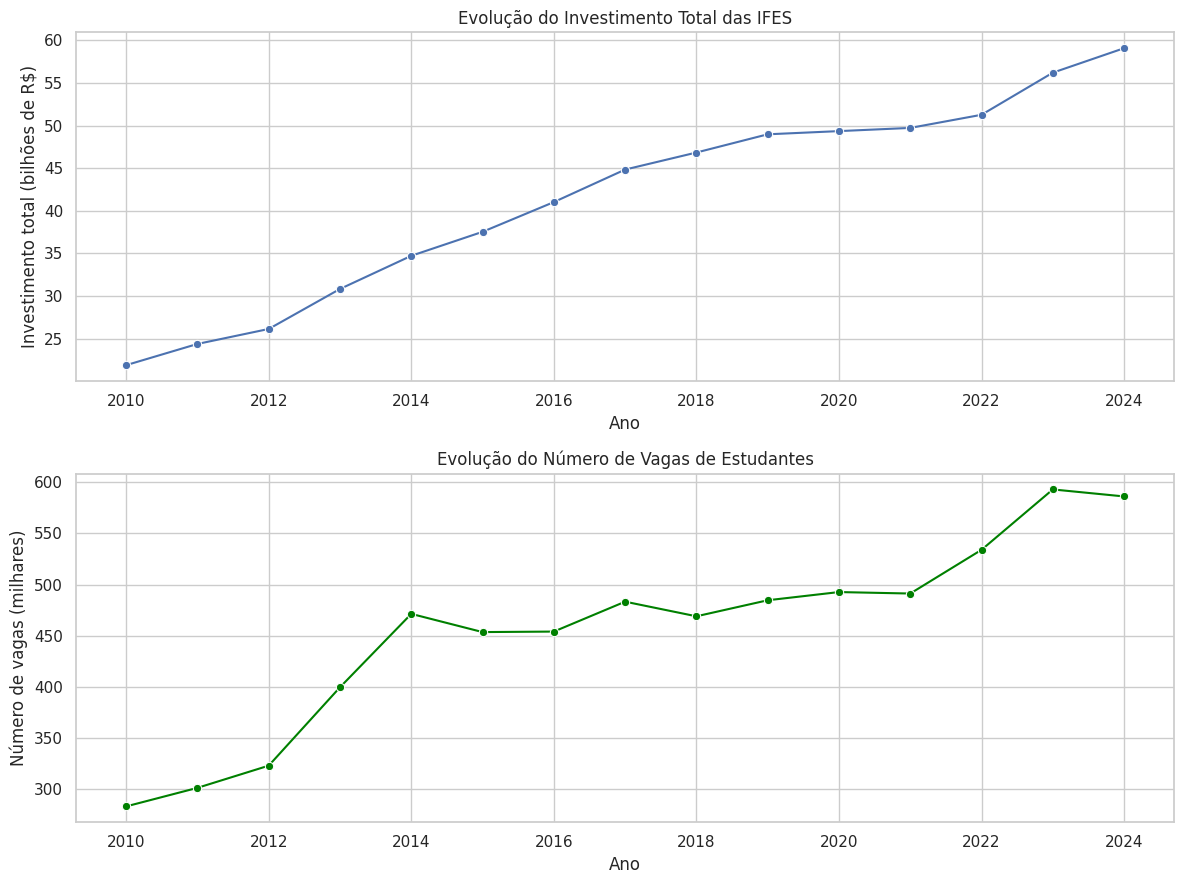

In [70]:
#OBS: foi optada a representação por ano e, como os dados já estão organizados por ano (2010 - 2024), não foi necessário o uso do groupby, conforme pedido.

fig, grafico = plt.subplots(2, 1, figsize=(12, 9))

# Gráfico 1: Investimento total
sns.lineplot(
    data=df_pandas,
    x='ano',
    y=df_pandas['investimento_total_ifes'] / 1e9,
    marker='o', #adiciona círculos sobre a linha ao longo dos anos
    ax=grafico[0]
)

grafico[0].set_title('Evolução do Investimento Total das IFES')
grafico[0].set_xlabel('Ano')
grafico[0].set_ylabel('Investimento total (bilhões de R$)')

# Gráfico 2: Vagas de estudantes
sns.lineplot(
    data=df_pandas,
    x='ano',
    y=df_pandas['num_vagas_estudantes'] / 1e3,
    marker='o',
    color='green',
    ax=grafico[1]
)

grafico[1].set_title('Evolução do Número de Vagas de Estudantes')
grafico[1].set_xlabel('Ano')
grafico[1].set_ylabel('Número de vagas (milhares)')

plt.tight_layout()
plt.show()

Para a análise da evolução do investimento total das IFES e do número de vagas de estudantes, optou-se por representações independentes devido às diferentes ordens de grandeza e unidades dos dados (reais e vagas, respectivamente). Para a exposição dos dados foi escolhido o gráfico de linhas, por ser um modelo bastante eficiente na comunicação visual da variação absoluta de dados numéricos ao longo dos anos. Além disso, as duas grandezas foram representadas com cores distintas e facilmente diferenciáveis (verde e azul), objetivando maior clareza.

##Etapa 2.3

,ano,estudante_por_docente,estudante_por_tae
0,2010,3.39,2.81
1,2011,3.33,2.74
2,2012,3.37,2.79
3,2013,3.94,3.45
4,2014,4.42,3.63
5,2015,4.08,3.39
6,2016,3.91,3.18
7,2017,4.04,3.37
8,2018,3.79,3.20
9,2019,3.81,3.68


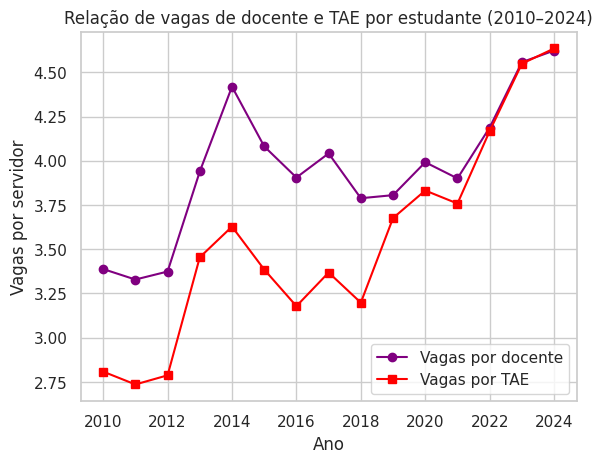

In [65]:

#Cálculo da relação de proporção entre vagas de estudante por vagas de docente/TAE
df_pandas["estudante_por_docente"] = df_pandas["num_vagas_estudantes"] / df_pandas["num_vagas_docente"]
df_pandas["estudante_por_tae"] = df_pandas["num_vagas_estudantes"] / df_pandas["num_vagas_tae"]
display(df_pandas[["ano", "estudante_por_docente", "estudante_por_tae"]].round(2))

#Plottagem do gráfico de linhas
fig, ax = plt.subplots()
ax.plot(df_pandas["ano"], df_pandas["estudante_por_docente"], marker="o", label="Vagas por docente", color='purple')
ax.plot(df_pandas["ano"], df_pandas["estudante_por_tae"], marker="s", label="Vagas por TAE", color='red')
ax.set_title("Relação de vagas de docente e TAE por estudante (2010–2024)")
ax.set_xlabel("Ano")
ax.set_ylabel("Vagas por servidor")
ax.legend()
plt.show()

Para apresentar as relações de vaga entre estudante e docente e estudante e TAE foi escolhido o gráfico de linhas, por permitir uma visualização clara e objetiva das variações de vaga (grandeza numérica) por servidor ao longo da faixa de anos definida (2010-2024). Além disso, a escolha de um único gráfico para representar as duas relações é bastante útil, permitindo a comparação direta entre ambas. Outro ponto a apontar-se foi a escolha de cores facilmente diferenciáveis e a inclusão de figuras geométricas sobre a linha ano a ano, possibilitando a identificação precisa dos anos.